# Phase 4 — Validation strategy

**Goal:** a score we can trust, built *before* we try models.

Why first? If the scoring is leaky, every later comparison is wrong, and you'd pick models
that are good at recognising *speakers* rather than *emotions*.

All the logic lives in [src/validation.py](../src/validation.py). This notebook shows what
it does and makes three data decisions.

In [10]:
import sys
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from validation import LABELS, cv_groups, evaluate, folds, load_training_data, pipeline, report

X, y, meta = load_training_data()
print(f'{X.shape[0]} clips x {X.shape[1]} features')
pd.crosstab(y, meta.dataset, margins=True)

4048 clips x 258 features


dataset,ravdess,tess,All
label,,,
angry,192,400,592
disgust,192,400,592
fear,192,400,592
happy,192,400,592
neutral,96,400,496
sad,192,400,592
surprised,192,400,592
All,1248,2800,4048


## 1. The folds: who is held out?

We use **5-fold cross-validation**. The data is split into 5 parts, and each part takes a
turn as the validation set while the model trains on the other 4. Every clip is
predicted exactly once, by a model that never saw it.

The key is *what* gets held out together. These units are called **groups**:
- **RAVDESS:** each **actor** is a group. Validation actors are completely unseen.
- **TESS:** only 2 speakers, so we can't hold a speaker out. Each **word** is a group
  instead, so validation words are unseen. The speakers are still familiar _(both being female voices)_, which makes
  TESS scores **optimistic**. That's why we report them separately.

In [11]:
rows = []
# Why is this not random?
for i, (train_idx, val_idx) in enumerate(folds(meta)):
    v, t = meta.iloc[val_idx], meta.iloc[train_idx]
    rv = v[v.dataset == 'ravdess']
    rows.append({'fold': i,
                 'val clips': len(v),
                 'val RAVDESS actors': ', '.join(sorted(rv.speaker.str[-2:].unique())),
                 'val actors F/M': f"{rv[rv.gender=='female'].speaker.nunique()}/{rv[rv.gender=='male'].speaker.nunique()}",
                 'val TESS words': v[v.dataset == 'tess'].text.nunique(),
                 'groups in both train & val': len(set(cv_groups(v)) & set(cv_groups(t)))})
pd.DataFrame(rows)

,fold,val clips,val RAVDESS actors,val actors F/M,val TESS words,groups in both train & val
0,0,820,"04, 09, 14, 19, 24",3/2,40,0
1,1,806,"03, 08, 13, 18, 23",2/3,39,0
2,2,806,"02, 07, 12, 17, 22",3/2,39,0
3,3,806,"01, 06, 11, 16, 21",2/3,39,0
4,4,810,"05, 10, 15, 20",2/2,43,0


**Check:** the last column must be 0 in every fold. No actor and no TESS word appears on
both sides, which is what makes the score honest.

## 2. The metric: macro F1

For each emotion, **F1** balances two questions:
- **Precision:** when the model says "angry", how often is it right?
- **Recall:** of all the truly angry clips, how many did it find?

**Macro F1** is the plain average of the 7 per-emotion F1 scores, so every emotion counts
equally. Plain accuracy would let a model ignore a rare class and still look good.

**`fold_std`** is how much the score varies between the 5 folds. Use it as a noise ruler:
**a difference between two models smaller than about `fold_std` is not a real difference.**

## 3. Baselines: the floor

Any real model must clearly beat these two:
- **most_frequent** always predicts the most common emotion.
- **stratified** guesses at random, in proportion to how common each emotion is.

In [12]:
results = []
for strategy in ['most_frequent', 'stratified']:
    scores, _ = evaluate(pipeline(DummyClassifier(strategy=strategy, random_state=0)), X, y, meta,
                         name=f'dummy ({strategy})')
    results.append(scores)
pd.DataFrame(results).round(3)

,model,macro_f1,fold_std,ravdess_f1,tess_f1
0,dummy (most_frequent),0.036,0.000,0.038,0.036
1,dummy (stratified),0.157,0.005,0.164,0.151


## 4. A reference model

**Logistic regression** is the simplest serious classifier. We use it here as a fixed
yardstick for the decisions in section 5, not to win. Phase 5 compares real candidates.

In [13]:
scores, pred = evaluate(pipeline(LogisticRegression(max_iter=2000)), X, y, meta, name='logreg')
results.append(scores)
pd.DataFrame(results).round(3)

,model,macro_f1,fold_std,ravdess_f1,tess_f1
0,dummy (most_frequent),0.036,0.000,0.038,0.036
1,dummy (stratified),0.157,0.005,0.164,0.151
2,logreg,0.823,0.020,0.490,0.966


              precision    recall  f1-score   support

       angry      0.844     0.875     0.859       592
     disgust      0.849     0.836     0.843       592
        fear      0.807     0.811     0.809       592
       happy      0.775     0.769     0.772       592
     neutral      0.879     0.849     0.864       496
         sad      0.784     0.823     0.803       592
   surprised      0.831     0.799     0.815       592

    accuracy                          0.822      4048
   macro avg      0.824     0.823     0.823      4048
weighted avg      0.823     0.822     0.822      4048



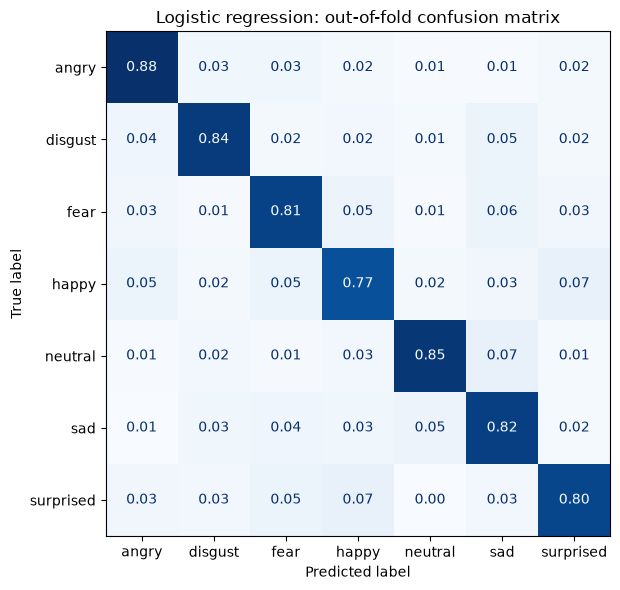

In [14]:
report(y, pred, meta, title='Logistic regression: out-of-fold confusion matrix')

**Reading the confusion matrix:** rows are the true emotion, columns are the prediction,
and each row sums to 1. The diagonal is the share predicted correctly. A bright
off-diagonal cell shows which emotion a class gets mistaken for.

## 5. Three data decisions

Each experiment changes **one thing** and keeps the same model and the same folds, so any
difference is caused by that one change.

| Experiment | Question |
|---|---|
| calm → neutral | Does training on the 192 calm clips as "neutral" help? (They are never scored.) |
| drop `raw_loudness_db` | Does pre-normalisation loudness help, or only identify the dataset? |
| drop `speech_s` | Clip length partly reflects the different texts in each dataset. Does it help? |

In [15]:
experiments = {
    'reference (calm dropped, all features)': {},
    'calm -> neutral':                        {'calm': 'neutral'},
    'drop raw_loudness_db':                   {'drop_features': ['raw_loudness_db']},
    'drop speech_s':                          {'drop_features': ['speech_s']},
    'drop both':                              {'drop_features': ['raw_loudness_db', 'speech_s']},
}
decision_rows = []
for name, kwargs in experiments.items():
    Xe, ye, me = load_training_data(**kwargs)
    s, _ = evaluate(pipeline(LogisticRegression(max_iter=2000)), Xe, ye, me, name=name)
    decision_rows.append(s)
decisions = pd.DataFrame(decision_rows).set_index('model')
decisions['change_vs_reference'] = decisions.macro_f1 - decisions.macro_f1.iloc[0]
decisions.round(3)

,macro_f1,fold_std,ravdess_f1,tess_f1,change_vs_reference
model,,,,,
"reference (calm dropped, all features)",0.823,0.020,0.490,0.966,0.000
calm -> neutral,0.824,0.024,0.494,0.968,0.001
drop raw_loudness_db,0.825,0.017,0.490,0.967,0.001
drop speech_s,0.822,0.022,0.488,0.966,-0.001
drop both,0.824,0.019,0.489,0.967,0.001


**Questions:**
1. How far above the dummy baselines is logistic regression?
2. Which dataset scores higher, and why should you trust the RAVDESS number more?
3. Which emotions get confused with each other most? Do the confusions make sense, given
   what you heard in Phase 2?
4. For each of the three decisions: is the change bigger than `fold_std`? What would you
   decide?

---
### Checkpoint (end of Phase 4)
In a markdown cell below, write:
1. In one sentence: why are folds grouped by actor and word instead of split randomly?
2. Your three decisions (calm, `raw_loudness_db`, `speech_s`), each with the number that
   justifies it.
3. The reference score Phase 5 has to beat.

**Answers:**
1. Logistic regression is way above the dummy baseline in terms of Macro F1 score: 82.3% vs. 15.7%.
2. TESS gave the best results with almost 96% F1 score, however the F1 score with RAVDESS is extremely poor. My hunch with RAVDESS numbers give a more distribution to the actors in the speech unlike the TESS dataset. So, better to trust the RAVDESS numbers.
3. Happy and surprised have the highest value apart from the diagonal in the confusion matrix. These 2 are the emotions are confused for the same. I don't know what you are referring to from Phase 2.
4. Yes the `fold_std` is higher for decisions 1 and 3. I would decide to drop raw_loudness_db just because it gives a better F1 score and has smaller `fold_std`.

### Checkpoint Answers:

1. If the validation and training split was done randomly, the same actor would appear on both the sets and then the model would just be able to recognize the voice of the actor and then give out the predicted label which is incorrect.
2. All the decisions changed the output metrics but not by any significant amount. We can just discard them as noise.
3. Phase 5 now has to beat the LR score of 82.5% overall F1 score whilst individual scores of RADVESS and TESS.